# Thor-31 Labeling supported missions using nearest neighour

## Background

Dataset contains column IMINT which identifies Image Int-missions.  In these
missions a dedicated aircraft like RF101 would fly to certain area and would
take photos of dedicated area.  These missions would support certain operation 
which should be in column Operation supported.


## Problem

Data set is missing a lot of SUPPORTEDMISSION labels.  Some of the file is
corrupted and some of them are missing them as such.  We have generated two
mutually exclusive columns which are:
    - operationhochiminhtrail, which contains:
        - name of the operation if known otherwise NULL
    - operationother, which contains name of the operation if it is not a direct 
      Ho Chi Minh trail operation

## Proposed solution

Calculate label based on k nearest neighbor.  Dimensions to be used are:
 - Latitude
 - Longitude
 - Date, which is converted as distance in days from minimum of missiondates



In [83]:
import pandas as pd

df = pd.read_parquet(
    "THOR_Analysis.parquet",
    columns=["THOR_DATA_VIET_ID", "missiondate_day","OPERATIONSUPPORTED","operationother", "operationhochiminhtrail","TGTLATDD_DDD_WGS84", "TGTLONDDD_DDD_WGS84"],
    filters=[("IMINT", "=", True)],
)

df["ishochiminhtrailoperation"] = pd.Series(pd.NA, index=df.index, dtype="Int64")
df.loc[df["operationhochiminhtrail"].notna(), "ishochiminhtrailoperation"] = 1
df.loc[df["operationother"].notna(), "ishochiminhtrailoperation"] = 0

In [84]:
df.head()

,THOR_DATA_VIET_ID,missiondate_day,OPERATIONSUPPORTED,operationother,operationhochiminhtrail,TGTLATDD_DDD_WGS84,TGTLONDDD_DDD_WGS84,ishochiminhtrailoperation
0,4054450,2494,NaN,NaN,NaN,16.302777,106.658888,<NA>
1,1565780,1255,IN COUNTRY - POLKA DOT-03,IN COUNTRY,NaN,14.357034,109.021565,0
2,1565792,364,IN COUNTRY,IN COUNTRY,NaN,15.662171,108.505904,0
3,1565803,677,IN COUNTRY - SOUTH VIETNAM,IN COUNTRY,NaN,15.405962,108.089954,0
4,1565809,1141,NaN,NaN,NaN,17.708000,106.447000,<NA>


## Split to training and validation datasets

In [85]:
from sklearn.model_selection import train_test_split

df_labeled = df[df["ishochiminhtrailoperation"].notna()].copy()
df_train, df_validation = train_test_split(
    df_labeled,
    test_size=0.2,
    random_state=42,
    stratify=df_labeled["ishochiminhtrailoperation"],
)

In [86]:
dataset_summary = pd.DataFrame([
    {
        "dataset": name,
        "row_count": len(dataset),
        "ho_chi_minh_trail_percent": round(dataset["ishochiminhtrailoperation"].eq(1).mean() * 100, 2),
    }
    for name, dataset in [("Training", df_train), ("Validation", df_validation)]
])
dataset_summary

,dataset,row_count,ho_chi_minh_trail_percent
0,Training,173100,41.6
1,Validation,43275,41.6


## Nearest-neighbor experiment

Sample size*trainpercentage training and size-(size*trainpercentage) validation observations, preserving label proportions. Select the number of neighbors using five-fold cross-validation on the training sample, then evaluate the selected model on the validation sample. Only mission day, latitude and longitude are used as features; scaling is fitted separately within each training fold.

Standardization gives each feature comparable variation, rather than a physical distance in space and time. The random split can place related missions or identical coordinates and dates in both sets, so validation scores may be optimistic.

In [87]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier

size = 100000
trainpercentage = 0.8

label = "ishochiminhtrailoperation"
features = ["missiondate_day", "TGTLATDD_DDD_WGS84", "TGTLONDDD_DDD_WGS84"]
train_sample, _ = train_test_split(
    df_train, train_size=int(size*trainpercentage), random_state=42, stratify=df_train[label]
)
validation_sample, _ = train_test_split(
    df_validation, train_size=int(size-(size*trainpercentage)), random_state=42, stratify=df_validation[label]
)

search = GridSearchCV(
    make_pipeline(StandardScaler(), KNeighborsClassifier()),
    {"kneighborsclassifier__n_neighbors": [1, 2, 3,4, 5,6, 11, 21, 51]},
    scoring="balanced_accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
)
search.fit(train_sample[features], train_sample[label].astype(int))
neighbor_results = pd.DataFrame({
    "neighbors": search.cv_results_["param_kneighborsclassifier__n_neighbors"],
    "mean_cv_balanced_accuracy": search.cv_results_["mean_test_score"],
    "std_cv_balanced_accuracy": search.cv_results_["std_test_score"],
})
neighbor_results

,neighbors,mean_cv_balanced_accuracy,std_cv_balanced_accuracy
0,1,0.968839,0.001220
1,2,0.961333,0.001119
2,3,0.969650,0.001124
3,4,0.966462,0.000801
4,5,0.969348,0.001762
5,6,0.967587,0.001458
6,11,0.968140,0.001380
7,21,0.966965,0.001768
8,51,0.962492,0.001718


In [88]:
validation_labels = validation_sample[label].astype(int)
validation_predictions = search.predict(validation_sample[features])
validation_results = pd.DataFrame([{
    "selected_neighbors": search.best_params_["kneighborsclassifier__n_neighbors"],
    "validation_rows": len(validation_sample),
    "accuracy": accuracy_score(validation_labels, validation_predictions),
    "balanced_accuracy": balanced_accuracy_score(validation_labels, validation_predictions),
}])
validation_results

,selected_neighbors,validation_rows,accuracy,balanced_accuracy
0,3,20000,0.97155,0.970629


In [89]:
pd.DataFrame(
    confusion_matrix(validation_labels, validation_predictions, labels=[0, 1]),
    index=pd.Index([0, 1], name="actual"),
    columns=pd.Index([0, 1], name="predicted"),
)

predicted,0,1
actual,,
0,11401,279
1,290,8030


## Full validation with three neighbors

Fit a three-neighbor classifier on the full training set and evaluate it on the full validation set. Scaling is fitted on training data only. The validation set includes the sample used in the earlier experiment, so these results are exploratory rather than a completely untouched final evaluation.

In [90]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

full_features = ["missiondate_day", "TGTLATDD_DDD_WGS84", "TGTLONDDD_DDD_WGS84"]
full_label = "ishochiminhtrailoperation"
full_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3))
full_model.fit(df_train[full_features], df_train[full_label].astype(int))
full_validation_labels = df_validation[full_label].astype(int)
full_validation_predictions = full_model.predict(df_validation[full_features])

full_validation_results = pd.DataFrame([{
    "neighbors": 3,
    "training_rows": len(df_train),
    "validation_rows": len(df_validation),
    "accuracy": accuracy_score(full_validation_labels, full_validation_predictions),
    "balanced_accuracy": balanced_accuracy_score(full_validation_labels, full_validation_predictions),
}])
full_validation_results

,neighbors,training_rows,validation_rows,accuracy,balanced_accuracy
0,3,173100,43275,0.975783,0.975223


In [91]:
pd.DataFrame(
    confusion_matrix(full_validation_labels, full_validation_predictions, labels=[0, 1]),
    index=pd.Index([0, 1], name="actual"),
    columns=pd.Index([0, 1], name="predicted"),
)

predicted,0,1
actual,,
0,24730,542
1,506,17497


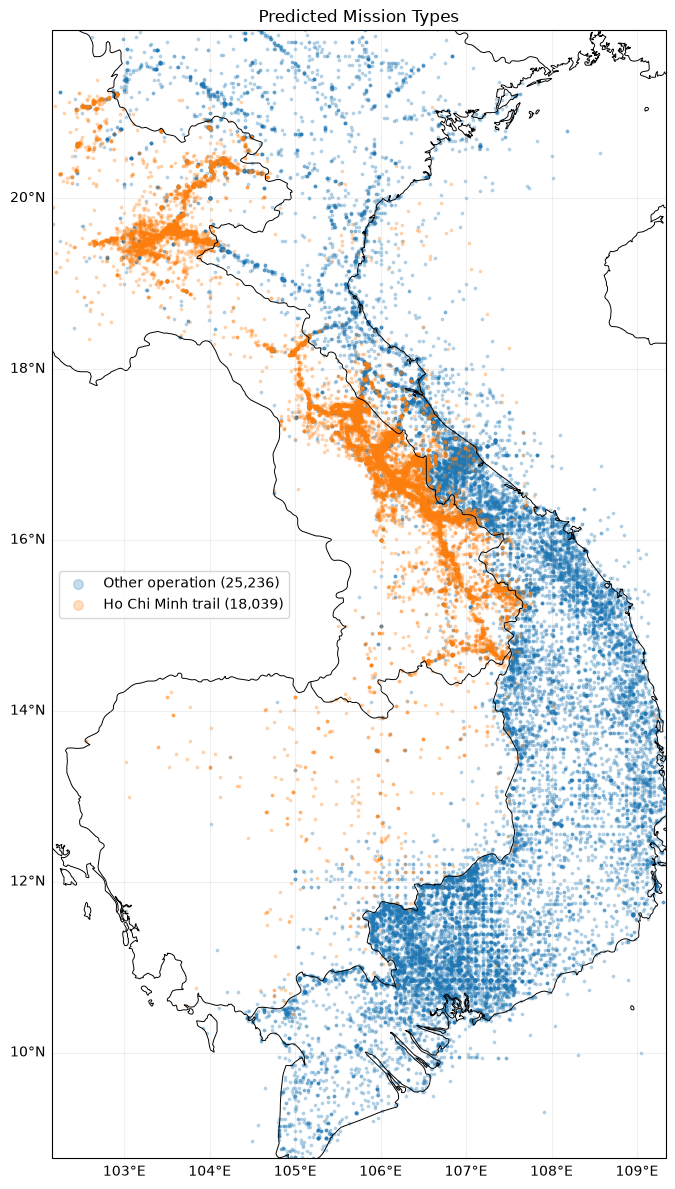

In [92]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

prediction_plot = df_validation.loc[:, ["TGTLATDD_DDD_WGS84", "TGTLONDDD_DDD_WGS84"]].copy()
prediction_plot["predicted"] = full_validation_predictions
prediction_plot["predicted_label"] = prediction_plot["predicted"].map({
    0: "Other operation",
    1: "Ho Chi Minh trail",
})

fig, ax = plt.subplots(figsize=(10, 12), subplot_kw={"projection": ccrs.PlateCarree()})

for predicted_class, label in [(0, "Other operation"), (1, "Ho Chi Minh trail")]:
    subset = prediction_plot[prediction_plot["predicted"] == predicted_class]
    ax.scatter(
        subset["TGTLONDDD_DDD_WGS84"],
        subset["TGTLATDD_DDD_WGS84"],
        s=3,
        alpha=0.25,
        transform=ccrs.PlateCarree(),
        label=f"{label} ({len(subset):,})",
    )

ax.set(
    title="Predicted Mission Types",
    xlabel="Longitude",
    ylabel="Latitude",
)
ax.set_extent([
    prediction_plot["TGTLONDDD_DDD_WGS84"].quantile(0.001),
    prediction_plot["TGTLONDDD_DDD_WGS84"].quantile(0.999),
    prediction_plot["TGTLATDD_DDD_WGS84"].quantile(0.001),
    prediction_plot["TGTLATDD_DDD_WGS84"].quantile(0.999),
], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.BORDERS, linewidth=0.7, edgecolor="black")
ax.coastlines(linewidth=0.7)
gridlines = ax.gridlines(draw_labels=True, alpha=0.2)
gridlines.top_labels = False
gridlines.right_labels = False
ax.legend(markerscale=4)
plt.tight_layout()
plt.show()

In [93]:
## Generating labels for the unknown

Use the three-neighbor model fitted on the training set to predict previously unlabeled IMINT observations. `df_with_predictions` keeps the original labels, stores model predictions separately, and provides a combined label column. Observations missing a model feature remain unlabeled.

In [94]:
df_with_predictions = df.copy()
unknown = df_with_predictions[full_label].isna()
eligible = unknown & df_with_predictions[full_features].notna().all(axis=1)
prediction_column = "predicted_ishochiminhtrailoperation"
df_with_predictions[prediction_column] = pd.Series(pd.NA, index=df.index, dtype="Int64")
if eligible.any():
    df_with_predictions.loc[eligible, prediction_column] = full_model.predict(
        df_with_predictions.loc[eligible, full_features]
    )
df_with_predictions["ishochiminhtrailoperation_completed"] = (
    df_with_predictions[full_label].fillna(df_with_predictions[prediction_column])
)
print(f"Predicted {eligible.sum():,} previously unlabeled observations.")
print(f"Remaining unlabeled due to missing features: {(unknown & ~eligible).sum():,}.")

Predicted 55,962 previously unlabeled observations.
Remaining unlabeled due to missing features: 0.


## Known and predicted operation labels

Compare known labels with predictions for previously unlabeled observations. Both maps use the same colors and geographic extent; overlapping points may obscure each other. Observations without a label or coordinates are not plotted.

Labeled observations without coordinates: 0
Observations without a known or predicted label: 0


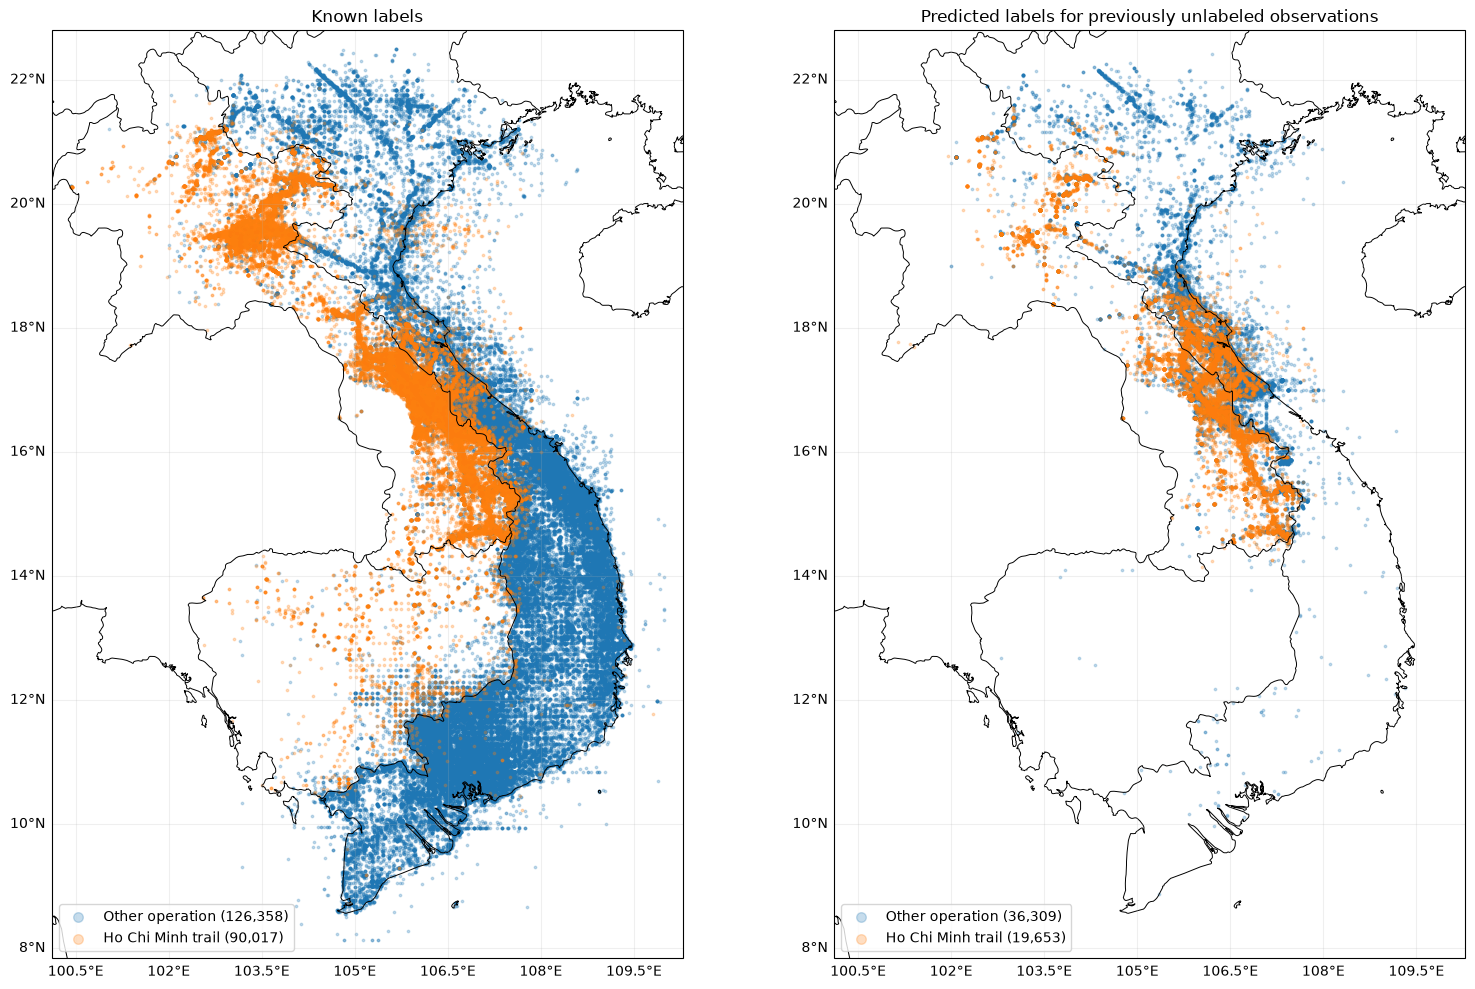

In [95]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

latitude = "TGTLATDD_DDD_WGS84"
longitude = "TGTLONDDD_DDD_WGS84"
known_label = "ishochiminhtrailoperation"
predicted_label = "predicted_ishochiminhtrailoperation"
has_label = df_with_predictions[known_label].notna() | df_with_predictions[predicted_label].notna()
map_data = df_with_predictions.loc[has_label].dropna(subset=[latitude, longitude])
if map_data.empty:
    raise ValueError("No labeled observations with coordinates to plot")
print(f"Labeled observations without coordinates: {has_label.sum() - len(map_data):,}")
print(f"Observations without a known or predicted label: {(~has_label).sum():,}")

extent = [
    map_data[longitude].min() - 0.3, map_data[longitude].max() + 0.3,
    map_data[latitude].min() - 0.3, map_data[latitude].max() + 0.3,
]
fig, axes = plt.subplots(1, 2, figsize=(16, 10), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, title, label_column in [
    (axes[0], "Known labels", known_label),
    (axes[1], "Predicted labels for previously unlabeled observations", predicted_label),
]:
    for value, label, color in [(0, "Other operation", "tab:blue"), (1, "Ho Chi Minh trail", "tab:orange")]:
        subset = map_data.loc[map_data[label_column] == value]
        ax.scatter(
            subset[longitude], subset[latitude], s=3, alpha=0.25, color=color,
            transform=ccrs.PlateCarree(), label=f"{label} ({len(subset):,})",
        )
    ax.set_title(title)
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.BORDERS, linewidth=0.7, edgecolor="black")
    ax.coastlines(linewidth=0.7)
    gridlines = ax.gridlines(draw_labels=True, alpha=0.2)
    gridlines.top_labels = False
    gridlines.right_labels = False
    ax.legend(loc="lower left", markerscale=4)
plt.tight_layout()
plt.show()

In [96]:
df_with_predictions.loc[df_with_predictions["ishochiminhtrailoperation_completed"]==1].head(100)

,THOR_DATA_VIET_ID,missiondate_day,OPERATIONSUPPORTED,operationother,operationhochiminhtrail,TGTLATDD_DDD_WGS84,TGTLONDDD_DDD_WGS84,ishochiminhtrailoperation,predicted_ishochiminhtrailoperation,ishochiminhtrailoperation_completed
0,4054450,2494,NaN,NaN,NaN,16.302777,106.658888,<NA>,1,1
7,1565853,1646,YANKEE TEIM - HEMP,NaN,YANKEE TEAM,17.583333,105.533333,1,<NA>,1
8,1565875,543,YANKEE TEIM - YANKEE TEAM,NaN,YANKEE TEAM,15.417000,107.100000,1,<NA>,1
11,1565927,1219,- HAGGLE,NaN,NaN,20.450000,104.166666,<NA>,1,1
16,1565946,262,YANKEE TEIM,NaN,YANKEE TEAM,15.367000,107.300000,1,<NA>,1
...,...,...,...,...,...,...,...,...,...,...
288,1568549,1443,YANKEE TEIM - SPICE,NaN,YANKEE TEAM,16.950000,106.850000,1,<NA>,1
290,1568633,260,NaN,NaN,NaN,18.166666,105.700000,<NA>,1,1
296,1568664,1422,YANKEE TEIM - TAME,NaN,YANKEE TEAM,16.300000,106.633000,1,<NA>,1
297,1568667,1111,NaN,NaN,NaN,17.674000,106.427000,<NA>,1,1


In [97]:
import joblib
joblib.dump(full_model, "model/hochiminhtrail-imint-knn.joblib")

['model/hochiminhtrail-imint-knn.joblib']